
# PR1 — Limpieza, EDA y visualización de *logs* de seguridad (Plantilla de trabajo)

**Estudiante:** _Torres Ansio, Alejandro_  

**Fecha:** _2026-11-02_  

**Dataset:** `data/PR1_security_logs_Mar2025.csv`

> Esta plantilla NO contiene soluciones. Incluye **estructura**, **pistas** y **TODOs** para guiar el trabajo.



## Objetivos y entregables

- Tratar datos de ciberseguridad: **ingesta → limpieza → normalización → EDA → visualización → detección de campañas → informe**.
- Usar `pandas`/`numpy` y graficar con `matplotlib` o `plotly`.
- Entregar:
  - `notebook/PR1_<apellidos>_<nombre>.ipynb` (este cuaderno completado)
  - `informe/informe_PR1_<apellidos>_<nombre>.pdf` (máx. 5 páginas)
  - `resultados/figuras/*.png|.html`
  - `resultados/eventos_flagged.csv`
  - `data/PR1_security_logs_Mar2025.csv`
  - `requirements.txt` o `environment.yml`


In [56]:

# === Configuración de entorno y rutas ===
from pathlib import Path

# Rutas base del proyecto (asume estructura de la plantilla)
BASE = Path().resolve()
DATA = BASE / "data" / "PR1_security_logs_Mar2025.csv"
OUT_DIR = BASE / "resultados"
FIG_DIR = OUT_DIR / "figuras"

# Crea carpetas de salida si no existen
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Semilla opcional (para reproducibilidad en muestreos, etc.)
SEED = 42

print("BASE:", BASE)
print("DATA:", DATA)
print("OUT_DIR:", OUT_DIR)
print("FIG_DIR:", FIG_DIR)


BASE: /content
DATA: /content/data/PR1_security_logs_Mar2025.csv
OUT_DIR: /content/resultados
FIG_DIR: /content/resultados/figuras


In [57]:

# === Importaciones ===
# Añade/retira según lo necesites. Evita librerías no permitidas.

import pandas as pd
import numpy as np
import re
import ipaddress
from datetime import datetime, timezone

# Para gráficos (elige UNO: matplotlib O plotly)
import matplotlib.pyplot as plt
# import plotly.express as px  # opcional

# NOTA: si usas matplotlib para esta PEC, no fijes estilos ni colores específicos.
# Cada gráfico debe ir en su propia figura: no uses subplots múltiples en la misma figura.


In [58]:

# === Utilidad opcional para guardar figuras ===
def save_figure(fig_name: str):
    """Guarda la figura activa en resultados/figuras."""
    assert fig_name, "Especifica un nombre para la figura, p.ej. 'req_por_dia.png'"
    path = FIG_DIR / fig_name
    plt.savefig(path, bbox_inches="tight", dpi=120)
    print("Figura guardada en:", path)



---
## Etapa A — Ingesta y *profiling* inicial

**Tareas:**  
- Carga el CSV en un `DataFrame` `df`.  
- Explora `shape`, `info()`, `describe()`, ejemplos de filas (`head()`, `tail()`).  
- Identifica tipos esperados vs reales; localiza nulos y valores inválidos (timestamps imposibles, IPs malformadas, `bytes_sent` vacíos).  
- Busca duplicados relevantes (decide la clave: ¿`event_id` único? ¿tupla clave?).

**Recomendaciones:**  
- Usa `pd.read_csv(..., low_memory=False)` si ves *dtypes* mezclados.  
- Declara `na_values=["", "-"]` si procede.  
- Documenta DECISIONES de limpieza que anticipas.


In [59]:
# TODO: Carga de datos y exploracion
df = pd.read_csv(DATA, low_memory=False)  # Rellena parámetros si lo consideras oportuno
na_values=["", "-"]

# Printear dimensiones (filas y columnas)
print(f"--- 1. DIMENSIONADO ---")
print("Shape:", df.shape)

# Tipos de datos, uso de memoria y valores no nulos por columna
print(f"\n--- 2. INFORMACION GENERAL ---")
df.info()

# Primeras y últimas filas para ver el formato real de los datos
print(f"\n--- 3. PRIMERAS FILAS ---")
display(df.head(3))

print(f"\n--- 4. ULTIMAS FILAS ---")
display(df.tail(3))

# Resumen estadístico de las columnas numéricas y categóricas
print(f"\n--- 5. RESUMEN ESTADISTICO ---")
display(df.describe(include='all'))

# Deja esta línea comentada una vez completada la carga:
# raise NotImplementedError("Carga del CSV en df (y profilado inicial)")

--- 1. DIMENSIONADO ---
Shape: (11775, 24)

--- 2. INFORMACION GENERAL ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11775 entries, 0 to 11774
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   event_id          11775 non-null  int64  
 1   timestamp         11744 non-null  object 
 2   src_ip            11775 non-null  object 
 3   src_port          11775 non-null  int64  
 4   src_country       11775 non-null  object 
 5   dest_ip           11775 non-null  object 
 6   dest_port         11775 non-null  int64  
 7   host              11775 non-null  object 
 8   http_method       11775 non-null  object 
 9   url_path          11775 non-null  object 
 10  query_string      2984 non-null   object 
 11  status            11775 non-null  int64  
 12  bytes_sent        11394 non-null  float64
 13  referrer          9069 non-null   object 
 14  user_agent        11775 non-null  object 
 15  protocol    

,event_id,timestamp,src_ip,src_port,src_country,dest_ip,dest_port,host,http_method,url_path,...,user_agent,protocol,http_version,tls_version,response_time_ms,event_source,waf_action,waf_rule_id,session_id,auth
0,3408,2025-03-10T10:26:00+00:00,198.51.100.124,13054,US,198.51.100.36,80,api.kaluma.io,POST,/cart,...,Mozilla/5.0 (iPhone; CPU iPhone OS 16_6 like M...,HTTP/1.1,1.1,NaN,22.0,apache,NaN,NaN,sid-706b94500819,user
1,1474,2025-03-05T10:26:08+00:00,198.51.100.87,64430,PL,198.51.100.190,443,cdn.sentryargo.org,GET,/images/logo.png,...,Mozilla/5.0 (Linux; Android 14; Pixel 8) Apple...,HTTP/3,1.1,TLS1.3,59.0,apache,NaN,NaN,sid-b4bdc36b9a6d,anonymous
2,9447,2025-03-26T14:31:37+00:00,198.51.100.87,25347,CN,198.51.100.36,80,m.kaluma.io,GET,/,...,Mozilla/5.0 (iPhone; CPU iPhone OS 16_6 like M...,HTTP/1.1,1.1,NaN,212.0,nginx,NaN,NaN,sid-2a79f7a16855,anonymous



--- 4. ULTIMAS FILAS ---


,event_id,timestamp,src_ip,src_port,src_country,dest_ip,dest_port,host,http_method,url_path,...,user_agent,protocol,http_version,tls_version,response_time_ms,event_source,waf_action,waf_rule_id,session_id,auth
11772,2284,2025-03-07T14:50:10+00:00,203.0.113.80,38080,IE,198.51.100.214,443,cdn.liforge.dev,GET,/checkout,...,Mozilla/5.0 (Macintosh; Intel Mac OS X 13_5) A...,HTTP/3,1.1,TLS1.3,668.0,apache,NaN,NaN,sid-0579e27a9eb1,anonymous
11773,10197,28/Mar/2025:02:06:55 +0000,203.0.113.138,33052,ES,203.0.113.192,443,cdn.kaluma.io,GET,/favicon.ico,...,Mozilla/5.0 (iPhone; CPU iPhone OS 16_6 like M...,HTTP/2,1.1,TLS1.3,845.0,nginx,NaN,NaN,NaN,-
11774,8800,2025-03-24T03:05:09+00:00,203.0.113.250,36667,IN,192.0.2.74,443,api.omnisynargo.net,HEAD,/.env,...,wpscan/3.8.25 (http://wpscan.com/wordpress-sec...,HTTP/2,1.1,TLS1.3,115.0,waf,NaN,NaN,NaN,-



--- 5. RESUMEN ESTADISTICO ---


,event_id,timestamp,src_ip,src_port,src_country,dest_ip,dest_port,host,http_method,url_path,...,user_agent,protocol,http_version,tls_version,response_time_ms,event_source,waf_action,waf_rule_id,session_id,auth
count,11775.000000,11744,11775,11775.000000,11775,11775,11775.000000,11775,11775,11775,...,11775,11775,1.177500e+04,8338,11775.00000,11775,461,475,6172,11775
unique,NaN,11477,1897,NaN,20,14,NaN,28,7,55,...,17,3,NaN,2,NaN,3,1,9,1883,3
top,NaN,2025/13/40 25:61:61,198.51.100.77,NaN,US,198.51.100.160,NaN,www.sentryargo.org,GET,/wp-login.php,...,Mozilla/5.0 (Macintosh; Intel Mac OS X 13_5) A...,HTTP/1.1,NaN,TLS1.3,NaN,nginx,BLOCK,CMDI-932160,sid-e6db1033c7ba,-
freq,NaN,101,1153,NaN,1012,2818,NaN,2175,7783,1571,...,1717,6573,NaN,7841,NaN,6075,461,96,12,3949
mean,5888.000000,NaN,NaN,33095.399151,NaN,NaN,367.563822,NaN,NaN,NaN,...,NaN,NaN,1.100000e+00,NaN,423.24000,NaN,NaN,NaN,NaN,NaN
std,3399.294044,NaN,NaN,18392.999885,NaN,NaN,147.290727,NaN,NaN,NaN,...,NaN,NaN,2.284936e-13,NaN,256.38381,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,1035.000000,NaN,NaN,80.000000,NaN,NaN,NaN,...,NaN,NaN,1.100000e+00,NaN,10.00000,NaN,NaN,NaN,NaN,NaN
25%,2944.500000,NaN,NaN,17111.000000,NaN,NaN,443.000000,NaN,NaN,NaN,...,NaN,NaN,1.100000e+00,NaN,199.50000,NaN,NaN,NaN,NaN,NaN
50%,5888.000000,NaN,NaN,32937.000000,NaN,NaN,443.000000,NaN,NaN,NaN,...,NaN,NaN,1.100000e+00,NaN,389.00000,NaN,NaN,NaN,NaN,NaN
75%,8831.500000,NaN,NaN,48921.000000,NaN,NaN,443.000000,NaN,NaN,NaN,...,NaN,NaN,1.100000e+00,NaN,644.00000,NaN,NaN,NaN,NaN,NaN


In [60]:
# Identifica tipos esperados vs reales; localiza nulos y valores inválidos y busqueda de duplicados relevantes

#Analisis de nulos
print(f"--- 1. VALORES NULOS POR COLUMNA ---")
# Creo un nuevo DataFrame auxiliar para calcular cuántos valores vacíos hay por columna y su porcentaje
nulos_df = pd.DataFrame({
    # df.isnull() busca los valores nulos (NaN) casilla por casilla, y .sum() los cuenta por columna
    'Nulos': df.isnull().sum(),
    # Calculo el porcentaje dividiendo los nulos de cada columna entre el total de filas del dataset (len(df)) y multiplicando por 100
    '% Nulos': (df.isnull().sum() / len(df)) * 100
})
# Filtro la tabla resultante para mostrar únicamente las columnas que tienen más de 0 nulos, descartando las que están limpias
display(nulos_df[nulos_df['Nulos'] > 0])

# Analisis de duplicados
print(f"\n --- 2. COMPROBACION DE DUPLICAOS ---")
# df.duplicated() busca filas que sean exactamente idénticas de principio a fin, y .sum() cuenta cuántas hay
duplicados_totales = df.duplicated().sum()
print(f"Filas totalmente duplicadas: {duplicados_totales}")

# Verifico si la columna 'event_id' existe y compruebo cuántos identificadores de eventos están repetidos
if 'event_id' in df.columns:
    duplicados_id = df.duplicated(subset=['event_id']).sum()
    print(f"Eventos con el mismo event_id repetido: {duplicados_id}")

--- 1. VALORES NULOS POR COLUMNA ---


,Nulos,% Nulos
timestamp,31,0.263270
query_string,8791,74.658174
bytes_sent,381,3.235669
referrer,2706,22.980892
tls_version,3437,29.188960
waf_action,11314,96.084926
waf_rule_id,11300,95.966030
session_id,5603,47.583864



 --- 2. COMPROBACION DE DUPLICAOS ---
Filas totalmente duplicadas: 0
Eventos con el mismo event_id repetido: 0



---
## Etapa B — Limpieza y normalización

**Objetivo:** crear columnas limpias y derivadas para facilitar el análisis.

**Requerido (nuevo esquema):**
- `ts` (datetime UTC) a partir de `timestamp` con parseo robusto.
- `http_method_norm` (método en mayúsculas).
- `bytes_sent_num` (numérico, decide tratamiento de vacíos).
- `status_class` ∈ {`2xx`,`3xx`,`4xx`,`5xx`}.
- `src_ip_kind` ∈ {`ipv4`,`ipv6`,`private`,`malformed`} usando `ipaddress`.
- Derivadas: `day`, `hour`, `weekday`, `is_weekend`, `is_asset` (extensión), `path_depth`, `has_query`, `query_len`.
- `ua_family` ∈ {`browser`,`bot`,`tool`,`rare`} (clasificación sencilla por patrones en `user_agent`).
- (Chequeo) `host_dest_consistent` (consistencia `host`↔`dest_ip`/`dest_port`).

**Pistas:**  
- Prueba primero `pd.to_datetime(..., errors="coerce", utc=True)`; si no basta, considera un *parser* por formatos.  
- `ipaddress.ip_address(x)` + `is_private` para IPs. Maneja `ValueError`.  
- Crea funciones pequeñas y testeables.


In [61]:

# === Stubs / esqueletos (completa las funciones) ===

def parse_timestamp_series(s: pd.Series) -> pd.Series:
    #Convierte 'timestamp' a datetime UTC robusto.

    # Limpio espacios en blanco en los extremos por si hay ruido
    s_clean = s.astype(str).str.strip()

    # 1ª pasada: intento con format='mixed'
    try:
        parsed = pd.to_datetime(s_clean, format='mixed', errors='coerce', utc=True)
    except ValueError:
        parsed = pd.to_datetime(s_clean, errors='coerce', utc=True)

    # 2ª pasada secuencial: si quedan nulos, pruebo formatos típicos de logs (Apache, ISO sin T, etc.)
    formatos_extra = [
        "%d/%b/%Y:%H:%M:%S %z",
        "%d/%b/%Y:%H:%M:%S",
        "%Y-%m-%d %H:%M:%S",
        "%Y/%m/%d %H:%M:%S"
    ]
    for fmt in formatos_extra:
        mask_na = parsed.isna() & s.notna()
        if not mask_na.any():
            break
        parsed.loc[mask_na] = pd.to_datetime(s_clean[mask_na], format=fmt, errors='coerce', utc=True)

    return parsed

    raise NotImplementedError


def classify_ip_value(ip_str: str) -> str:
    """Clasifica IP en {'ipv4','ipv6','private','malformed'}."""

    if pd.isna(ip_str):
        return 'malformed'
    try:
        # Limpio espacios y convierto a objeto IP
        ip_obj = ipaddress.ip_address(str(ip_str).strip())
        if ip_obj.is_private:
            return 'private'
        return 'ipv4' if ip_obj.version == 4 else 'ipv6'
    except ValueError:
        # Si ipaddress lanza ValueError (ejemplo: "999.999.1.1" o texto corrupto)
        return 'malformed'

    raise NotImplementedError


def normalize_http_method(x: str) -> str:
    """Normaliza método HTTP a mayúsculas; maneja nulos."""

    if pd.isna(x):
        return np.nan
    val = str(x).strip().upper()
    return val if val != '' else np.nan

    raise NotImplementedError


def status_to_class(code: int) -> str:
    """Mapea 200-299→'2xx', 300-399→'3xx', 400-499→'4xx', 500-599→'5xx'."""

    if pd.isna(code):
        return np.nan
    try:
        c = int(code)
        if 200 <= c < 300:
            return '2xx'
        elif 300 <= c < 400:
            return '3xx'
        elif 400 <= c < 500:
            return '4xx'
        elif 500 <= c < 600:
            return '5xx'
        else:
            return 'other'
    except (ValueError, TypeError):
        return np.nan

    raise NotImplementedError


def ua_to_family(ua: str) -> str:
    """Clasifica user-agent en {'browser','bot','tool','rare'} con reglas simples."""

    if pd.isna(ua) or str(ua).strip() == '':
        return 'rare'

    ua_lower = str(ua).lower()

    # Herramientas de ataque, scripting o testing habituales en logs
    tools = ['curl', 'sqlmap', 'wpscan', 'python-requests', 'nmap', 'nikto', 'burpsuite', 'gobuster', 'hydra']
    if any(t in ua_lower for t in tools):
        return 'tool'

    # Bots de indexación o rastreo conocidos
    bots = ['googlebot', 'bingbot', 'duckduckbot', 'baiduspider', 'yandexbot', 'ia_archiver', 'semrushbot']
    if any(b in ua_lower for b in bots):
        return 'bot'

    # Navegadores web legítimos comunes
    browsers = ['mozilla', 'chrome', 'safari', 'firefox', 'edge', 'opera']
    if any(b in ua_lower for b in browsers):
        return 'browser'

    return 'rare'

    raise NotImplementedError


In [62]:

# TODO: Aplica transformaciones para crear columnas limpias/derivadas.

# Aplicación de transformaciones y creación de columnas limpias y derivadas
df['ts'] = parse_timestamp_series(df['timestamp'])
df['http_method_norm'] = df['http_method'].apply(normalize_http_method)
df['bytes_sent_num'] = pd.to_numeric(df['bytes_sent'], errors='coerce')
df['status_class'] = df['status'].apply(status_to_class)
df['src_ip_kind'] = df['src_ip'].apply(classify_ip_value)

# Variables derivadas temporales a partir de 'ts'
df['day'] = df['ts'].dt.date
df['hour'] = df['ts'].dt.hour
df['weekday'] = df['ts'].dt.weekday
df['is_weekend'] = df['weekday'].isin([5,6])

# Variables derivadas de navegación y URL
df['is_asset'] = df['url_path'].str.endswith(('.js','.css','.png','.ico'), na=False)
df['path_depth'] = df['url_path'].fillna('').str.count('/')
df['has_query'] = df['query_string'].fillna('') != ''
df['query_len'] = df['query_string'].fillna('').str.len()

# Clasificación del User-Agent
df['ua_family'] = df['user_agent'].apply(ua_to_family)

# TODO: host_dest_consistent (regla propia y justificación en el informe)
def check_host_consistency(row):
    """Verifica si el host y el puerto de destino guardan coherencia lógica."""
    host = str(row.get('host', '')).lower()
    port = row.get('dest_port')

    if pd.isna(host) or pd.isna(port):
        return True # Por defecto asumimos coherencia si faltan metadatos extremos

    try:
        p = int(port)
    except (ValueError, TypeError):
        return False

    # Regla de coherencia: servicios web estándar deben apuntar a 80 o 443
    # Si es un entorno de pruebas o puertos internos específicos (ej. 8080, 8443), también los admito
    puertos_web_validos = [80, 443, 8080, 8443, 3000]

    if p in puertos_web_validos:
        return True

    # Si usa puertos inusuales para tráfico web estándar, marco incoherencia potencial
    return False

df['host_dest_consistent'] = df.apply(check_host_consistency, axis=1)

# raise NotImplementedError("Completa la normalización y columnas derivadas")


In [63]:
# === Métricas cuantitativas de la Etapa B para el informe ===

# 1. Porcentaje de IPs privadas y malformadas
total_ips = len(df)
privadas_count = (df['src_ip_kind'] == 'private').sum()
malformadas_count = (df['src_ip_kind'] == 'malformed').sum()

pct_privadas = (privadas_count / total_ips) * 100
pct_malformadas = (malformadas_count / total_ips) * 100

print(f"--- 1. Clasificación de IPs ---")
print(f"IPs privadas: {privadas_count} ({pct_privadas:.2f}%)")
print(f"IPs malformadas: {malformadas_count} ({pct_malformadas:.2f}%)")

# 2. Conteo de filas con timestamp nulo tras el parseo
ts_nulos = df['ts'].isna().sum()
pct_ts_nulos = (ts_nulos / total_ips) * 100

print(f"\n--- 2. Parseo de Timestamp ---")
print(f"Filas con 'ts' nulo tras el parseo: {ts_nulos} ({pct_ts_nulos:.2f}%)")
print("Estrategia adoptada: Se mantienen como NaT para evitar sesgos temporales e invalidar análisis de ráfagas.")

# 3. Detección de incoherencias entre host y destino
incoherentes_count = (~df['host_dest_consistent']).sum()
pct_incoherentes = (incoherentes_count / total_ips) * 100

print(f"\n--- 3. Consistencia Host <--> Destino ---")
print(f"Registros con incoherencias detectadas: {incoherentes_count} ({pct_incoherentes:.2f}%)")

--- 1. Clasificación de IPs ---
IPs privadas: 11718 (99.52%)
IPs malformadas: 57 (0.48%)

--- 2. Parseo de Timestamp ---
Filas con 'ts' nulo tras el parseo: 132 (1.12%)
Estrategia adoptada: Se mantienen como NaT para evitar sesgos temporales e invalidar análisis de ráfagas.

--- 3. Consistencia Host <--> Destino ---
Registros con incoherencias detectadas: 0 (0.00%)



---
## Etapa C — EDA y visualizaciones

**Requerido (guardar figuras en `resultados/figuras/`):**
- Serie temporal diaria (req/día).
- Heatmap hora×día.
- Barras apiladas: `status_class` por `host`, y por `ua_family`.
- Rankings: top IPs por **404**; top `url_path`.
- Histograma de `response_time_ms` (y, si quieres, boxplots por `host`).
- Gráfico libre con *insight* propio.

> Recuerda: con matplotlib, **una figura por gráfico** y evita fijar colores/estilos.


Figura guardada en: /content/resultados/figuras/req_por_dia.png
Figura guardada en: /content/resultados/figuras/heatmap_hora_dia.png
Figura guardada en: /content/resultados/figuras/status_por_host.png
Figura guardada en: /content/resultados/figuras/status_por_uafamily.png
Figura guardada en: /content/resultados/figuras/top_ips_404.png
Figura guardada en: /content/resultados/figuras/top_url_paths.png
Figura guardada en: /content/resultados/figuras/histograma_response_time.png
Figura guardada en: /content/resultados/figuras/insight_path_depth_status.png


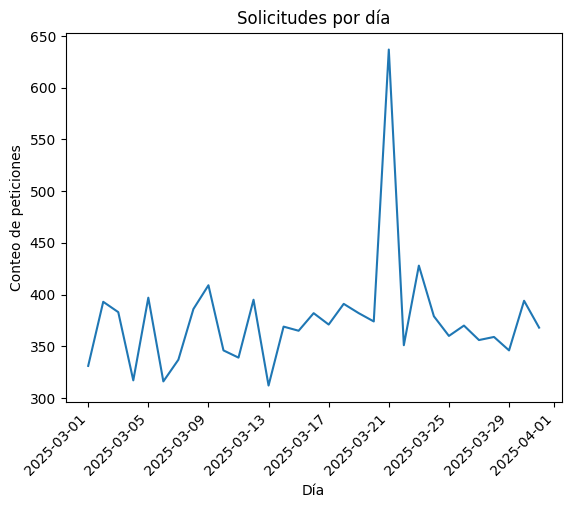

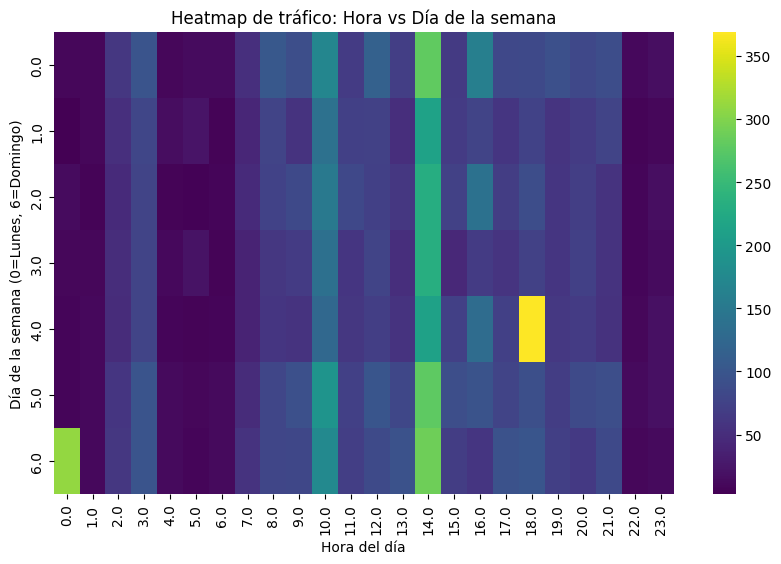

<Figure size 1000x600 with 0 Axes>

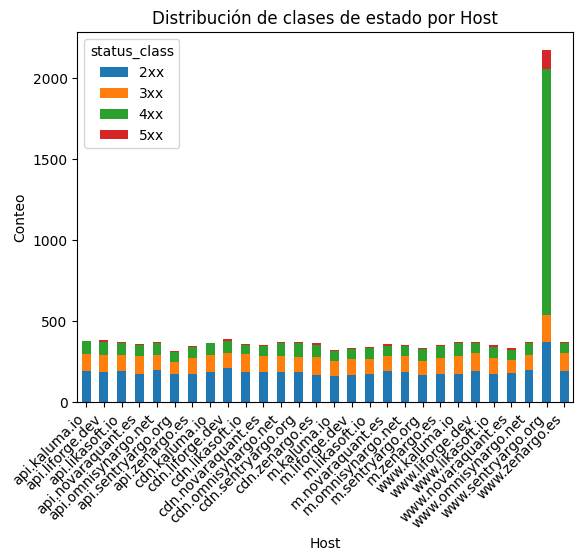

<Figure size 1000x600 with 0 Axes>

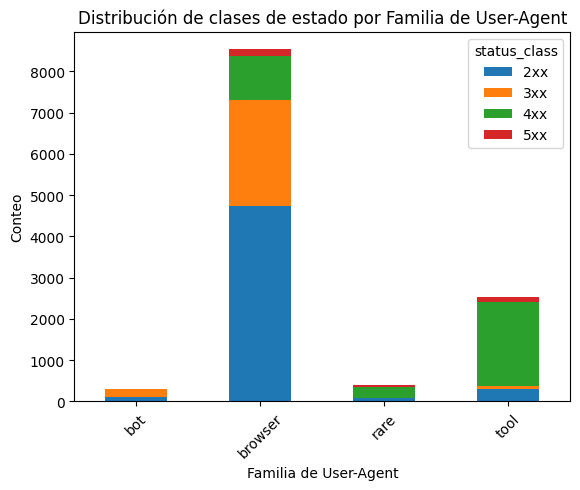

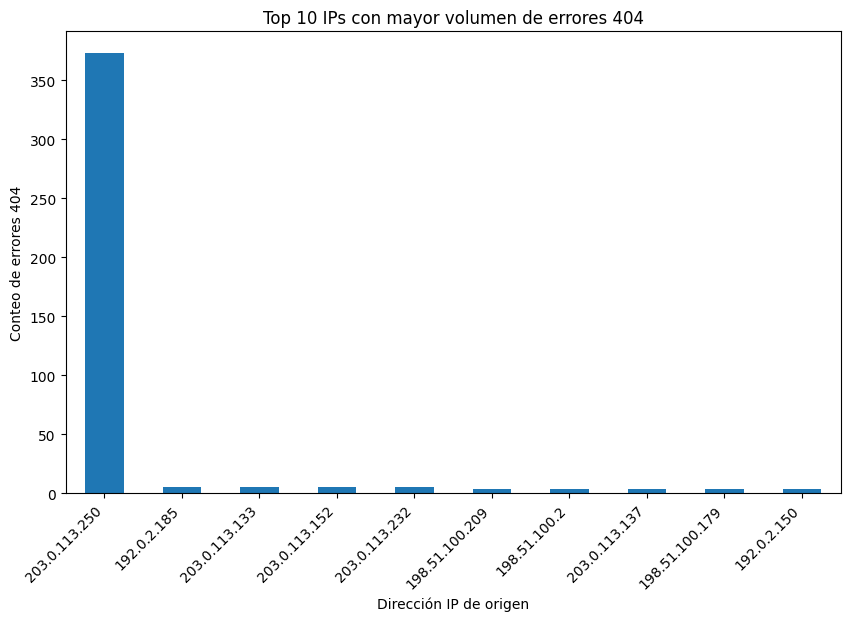

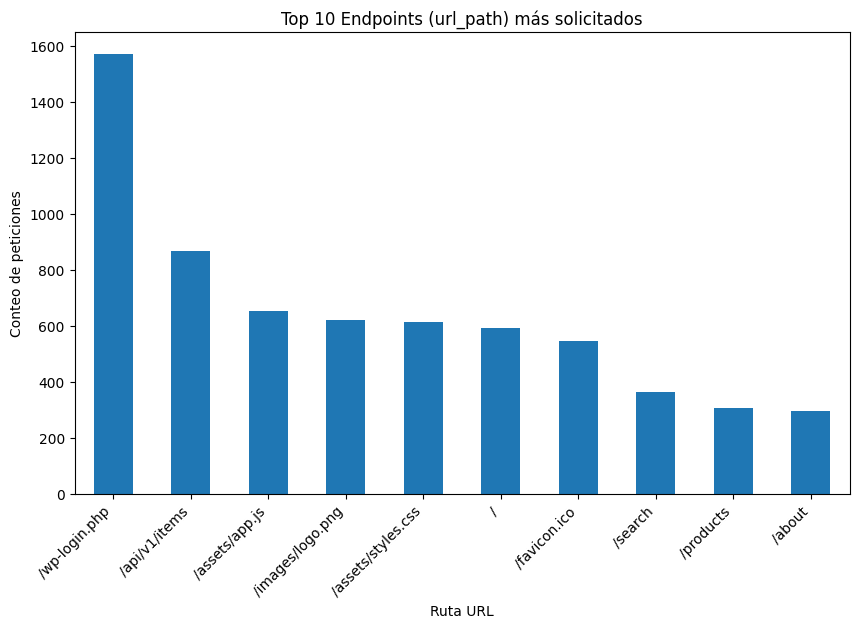

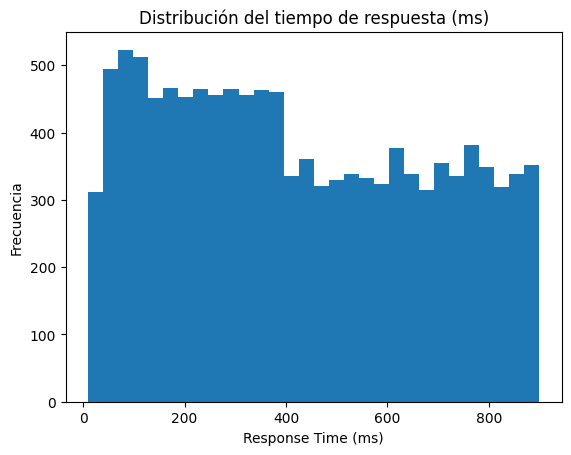

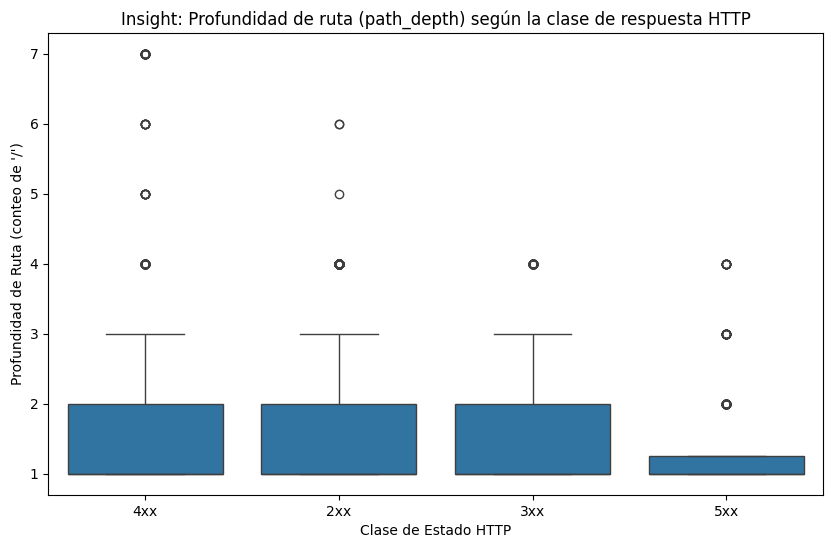

In [64]:

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Serie temporal diaria (req/día)
plt.figure()
df.groupby(df['ts'].dt.date).size().plot(kind='line')
plt.title("Solicitudes por día")
plt.xlabel("Día")
plt.ylabel("Conteo de peticiones")
plt.xticks(rotation=45, ha='right')
save_figure("req_por_dia.png")

# 2. Heatmap hora × día de la semana
# Se ajusta figsize=(10, 6) para garantizar que las celdas de la matriz tengan
# una proporción visual adecuada y las etiquetas de las 24 horas y días no se compriman.
plt.figure(figsize=(10, 6))
heatmap_data = df.groupby([df['ts'].dt.weekday, df['ts'].dt.hour]).size().unstack(fill_value=0)
sns.heatmap(heatmap_data, cmap='viridis')
plt.title("Heatmap de tráfico: Hora vs Día de la semana")
plt.xlabel("Hora del día")
plt.ylabel("Día de la semana (0=Lunes, 6=Domingo)")
save_figure("heatmap_hora_dia.png")

# 3. Barras apiladas: status_class por host
# Se ajusta figsize=(10, 6) debido a que los nombres de los distintos hosts en el eje X
# son largos y requieren rotación y espacio adicional para evitar que las etiquetas se solapen.
plt.figure(figsize=(10, 6))
status_host = pd.crosstab(df['host'], df['status_class'])
status_host.plot(kind='bar', stacked=True)
plt.title("Distribución de clases de estado por Host")
plt.xlabel("Host")
plt.ylabel("Conteo")
plt.xticks(rotation=45, ha='right')
save_figure("status_por_host.png")

# 4. Barras apiladas: status_class por ua_family
# Se ajusta figsize=(10, 6) para ofrecer espacio horizontal suficiente a las categorías
# de familia de agentes de usuario (browser, bot, tool, rare) y evitar apelotonamientos.
plt.figure(figsize=(10, 6))
status_ua = pd.crosstab(df['ua_family'], df['status_class'])
status_ua.plot(kind='bar', stacked=True)
plt.title("Distribución de clases de estado por Familia de User-Agent")
plt.xlabel("Familia de User-Agent")
plt.ylabel("Conteo")
plt.xticks(rotation=45)
save_figure("status_por_uafamily.png")

# 5. Ranking: Top IPs por errores 404
# Se ajusta figsize=(10, 6) porque las direcciones IP en formato texto (IPv4/IPv6)
# ocupan anchura y exigen rotación en el eje X para mantener la legibilidad del ranking.
plt.figure(figsize=(10, 6))
top_404_ips = df[df['status'] == 404]['src_ip'].value_counts().head(10)
top_404_ips.plot(kind='bar')
plt.title("Top 10 IPs con mayor volumen de errores 404")
plt.xlabel("Dirección IP de origen")
plt.ylabel("Conteo de errores 404")
plt.xticks(rotation=45, ha='right')
save_figure("top_ips_404.png")

# 6. Ranking: Top url_path más solicitados
# Se ajusta figsize=(10, 6) ya que las rutas de los endpoints web suelen ser extensas
# y necesitan espacio horizontal y rotación para distinguirse con claridad.
plt.figure(figsize=(10, 6))
top_paths = df['url_path'].value_counts().head(10)
top_paths.plot(kind='bar')
plt.title("Top 10 Endpoints (url_path) más solicitados")
plt.xlabel("Ruta URL")
plt.ylabel("Conteo de peticiones")
plt.xticks(rotation=45, ha='right')
save_figure("top_url_paths.png")

# 7. Histograma de response_time_ms
plt.figure()
df['response_time_ms'].dropna().plot(kind='hist', bins=30)
plt.title("Distribución del tiempo de respuesta (ms)")
plt.xlabel("Response Time (ms)")
plt.ylabel("Frecuencia")
save_figure("histograma_response_time.png")

# 8. Gráfico libre con insight propio: Relación profundidad de ruta vs código de estado
# Se ajusta figsize=(10, 6) dado que un boxplot agrupado por categorías discretas en el eje X
# se beneficia de un área de ploteo más amplia para comparar visualmente las medianas y dispersiones.
plt.figure(figsize=(10, 6))
sns.boxplot(x='status_class', y='path_depth', data=df)
plt.title("Insight: Profundidad de ruta (path_depth) según la clase de respuesta HTTP")
plt.xlabel("Clase de Estado HTTP")
plt.ylabel("Profundidad de Ruta (conteo de '/')")
save_figure("insight_path_depth_status.png")



---
## Etapa D — Detección de patrones y campañas (reglas + evidencias)

Genera `resultados/eventos_flagged.csv` con cabecera:  
`event_id,ts,src_ip,host,url_path,status,attack_type,rule,evidence,severity`

**Campañas a detectar (una función por campaña):**
- Scanner 404/403 diario (~03:05).
- Fuerza bruta a WordPress (~14:10; domingo 00:00 extra).
- SQLi (lun/mié/vie ~16:20).
- LFI/Traversal (mar/jue ~05:45).
- XSS (diario ~12:30).
- Command injection (días alternos ~18:05).
- Rate limiting 429 (diario 10:00).
- Micro‑DDoS (21‑Mar 18:47–18:48).

**Estructura sugerida:** cada función devuelve **un DataFrame** con las columnas requeridas.


In [65]:

# === Esqueletos de detección (rellena con tu lógica) ===
# Sugerencia: usa ventanas temporales (resample a '1T' o '1S'), groupby por IP/host, y umbrales.

def detect_scanner(df: pd.DataFrame) -> pd.DataFrame:
    """Regla ejemplo (personaliza):
    - ≥ N peticiones con 404/403 a endpoints sensibles desde la misma IP en ≤ 2 minutos.
    Devuelve DataFrame con columnas requeridas.
    """

    # Filtramos solo los errores de cliente sospechosos
    df_scan = df[df['status'].isin([404, 403])].copy()
    df_scan = df_scan.set_index('ts')

    eventos_flagged = []
    # Agrupamos por IP de origen
    for ip, group in df_scan.groupby('src_ip'):
        # Contamos peticiones en ventanas de 2 minutos
        counts = group.resample('2T').size()
        peaks = counts[counts >= 10]  # Umbral: 10 errores en 2 mins

        for peak_time in peaks.index:
            window_end = peak_time + pd.Timedelta(minutes=2)
            events = group[(group.index >= peak_time) & (group.index < window_end)]

            for _, row in events.iterrows():
                eventos_flagged.append({
                    'event_id': row['event_id'], 'ts': row.name, 'src_ip': row['src_ip'],
                    'host': row['host'], 'url_path': row['url_path'], 'status': row['status'],
                    'attack_type': 'scanner_404_403',
                    'rule': '>= 10 errores 404/403 en 2 min desde la misma IP',
                    'evidence': f"Pico detectado a las {peak_time.strftime('%H:%M')}",
                    'severity': 'medium'
                })

    return pd.DataFrame(eventos_flagged).drop_duplicates(subset=['event_id'])

    raise NotImplementedError


def detect_bruteforce_wp(df: pd.DataFrame) -> pd.DataFrame:
    """Detecta ráfagas POST a /wp-login.php con mayoría 401 desde misma IP→host,
    marcando si culmina en 302/200.
    """

    mask = (df['url_path'] == '/wp-login.php') & (df['http_method_norm'] == 'POST')
    df_wp = df[mask].copy().set_index('ts')

    eventos_flagged = []
    for (ip, host), group in df_wp.groupby(['src_ip', 'host']):
        counts = group.resample('1T').size()
        peaks = counts[counts >= 5]  # Umbral: 5 POSTs en 1 minuto

        for peak_time in peaks.index:
            window_end = peak_time + pd.Timedelta(minutes=1)
            events = group[(group.index >= peak_time) & (group.index < window_end)]

            # Verificamos si lograron entrar (código 200 o redirección 302)
            success = events['status'].isin([200, 302]).any()
            evidence_msg = f"Ráfaga POST. Acceso exitoso: {success}"
            sev = 'high' if success else 'medium'

            for _, row in events.iterrows():
                eventos_flagged.append({
                    'event_id': row['event_id'], 'ts': row.name, 'src_ip': row['src_ip'],
                    'host': row['host'], 'url_path': row['url_path'], 'status': row['status'],
                    'attack_type': 'bruteforce_wp',
                    'rule': '>= 5 POST a wp-login.php en 1 min',
                    'evidence': evidence_msg,
                    'severity': sev
                })

    return pd.DataFrame(eventos_flagged).drop_duplicates(subset=['event_id'])

    raise NotImplementedError


def detect_sqli(df: pd.DataFrame) -> pd.DataFrame:
    """Patrones en query_string (UNION SELECT, ' OR '1'='1, --), cruzado con WAF SQLI-...."""

    pattern = r"(?i)(union\s+select|or\s+'1'='1|--|')"

    mask_query = df['query_string'].str.contains(pattern, na=False)
    mask_waf = df['waf_rule_id'].str.startswith('SQLI', na=False)

    out = df[mask_query | mask_waf].copy()
    out['attack_type'] = 'sqli'
    out['rule'] = "Regex SQLi o alerta WAF SQLI-..."
    out['evidence'] = "Patrón malicioso encontrado en la consulta URL o bloqueado por WAF"
    out['severity'] = 'high'

    return out[['event_id', 'ts', 'src_ip', 'host', 'url_path', 'status', 'attack_type', 'rule', 'evidence', 'severity']]

    raise NotImplementedError


def detect_lfi_traversal(df: pd.DataFrame) -> pd.DataFrame:
    """Patrones ../, %2e%2e y rutas sensibles; valida con reglas LFI/TRAVERSAL."""

    pattern = r"(?i)(\.{2}/|%2e%2e|/etc/passwd|/var/log)"

    mask_path = df['url_path'].str.contains(pattern, na=False)
    mask_query = df['query_string'].str.contains(pattern, na=False)
    mask_waf = df['waf_rule_id'].str.contains('LFI|TRAVERSAL', na=False)

    out = df[mask_path | mask_query | mask_waf].copy()
    out['attack_type'] = 'lfi_traversal'
    out['rule'] = "Regex ../ o /etc/passwd o regla WAF LFI/TRAVERSAL"
    out['evidence'] = "Intento de escalado de directorios o lectura de archivos sensibles"
    out['severity'] = 'high'

    return out[['event_id', 'ts', 'src_ip', 'host', 'url_path', 'status', 'attack_type', 'rule', 'evidence', 'severity']]

    raise NotImplementedError


def detect_xss(df: pd.DataFrame) -> pd.DataFrame:
    """Patrones <script>, onerror=...; contrasta user-agent/host y WAF XSS-...."""

    pattern = r"(?i)(<script|onerror=)"

    mask_query = df['query_string'].str.contains(pattern, na=False)
    mask_path = df['url_path'].str.contains(pattern, na=False)
    mask_waf = df['waf_rule_id'].str.startswith('XSS', na=False)

    out = df[mask_query | mask_path | mask_waf].copy()
    out['attack_type'] = 'xss'
    out['rule'] = "Regex <script/onerror o alerta WAF XSS-..."
    out['evidence'] = "Patrón de inyección de código cliente detectado"
    out['severity'] = 'high'

    return out[['event_id', 'ts', 'src_ip', 'host', 'url_path', 'status', 'attack_type', 'rule', 'evidence', 'severity']]

    raise NotImplementedError


def detect_cmdi(df: pd.DataFrame) -> pd.DataFrame:
    """Patrones ';cat /etc/passwd', 'cmd='...; valida con WAF CMDI-...."""

    pattern = r"(?i)(;\s*cat\s*/etc/|cmd=)"

    mask_query = df['query_string'].str.contains(pattern, na=False)
    mask_path = df['url_path'].str.contains(pattern, na=False)
    mask_waf = df['waf_rule_id'].str.startswith('CMDI', na=False)

    out = df[mask_query | mask_path | mask_waf].copy()
    out['attack_type'] = 'cmdi'
    out['rule'] = "Regex cmd= o /etc/ o alerta WAF CMDI-..."
    out['evidence'] = "Intento de ejecución de comandos en el servidor"
    out['severity'] = 'high'

    return out[['event_id', 'ts', 'src_ip', 'host', 'url_path', 'status', 'attack_type', 'rule', 'evidence', 'severity']]

    raise NotImplementedError


def detect_rate_limit(df: pd.DataFrame) -> pd.DataFrame:
    """Picos de 429 en /api/v1/items desde misma IP; calcula ratio 429/total por día."""

    mask = (df['url_path'] == '/api/v1/items') & (df['status'] == 429)
    df_rl = df[mask].copy().set_index('ts')

    eventos_flagged = []
    for ip, group in df_rl.groupby('src_ip'):
        counts = group.resample('1H').size()
        peaks = counts[counts >= 10]  # Umbral temporal para considerar abuso

        for peak_time in peaks.index:
            window_end = peak_time + pd.Timedelta(hours=1)
            events = group[(group.index >= peak_time) & (group.index < window_end)]

            for _, row in events.iterrows():
                eventos_flagged.append({
                    'event_id': row['event_id'], 'ts': row.name, 'src_ip': row['src_ip'],
                    'host': row['host'], 'url_path': row['url_path'], 'status': row['status'],
                    'attack_type': 'rate_limiting',
                    'rule': 'Picos de errores 429 en /api/v1/items',
                    'evidence': f"Abuso de cuota de API detectado a las {peak_time.strftime('%H:%M')}",
                    'severity': 'medium'
                })

    return pd.DataFrame(eventos_flagged).drop_duplicates(subset=['event_id'])

    raise NotImplementedError


def detect_micro_ddos(df: pd.DataFrame) -> pd.DataFrame:
    """Micro-brote de 60–120s con req/s altos a mismo host desde múltiples IPs
    y aumento de 5xx/429; devuelve eventos representativos del intervalo.
    """

    df_ts = df.set_index('ts')
    eventos_flagged = []

    for host, group in df_ts.groupby('host'):
        counts = group.resample('1T').size()
        peaks = counts[counts >= 50]  # Umbral: Más de 50 req/min hacia un mismo host

        for peak_time in peaks.index:
            window_end = peak_time + pd.Timedelta(minutes=1)
            events = group[(group.index >= peak_time) & (group.index < window_end)]

            ips_count = events['src_ip'].nunique()
            err_rate = events['status'].isin([500, 502, 503, 429]).mean()

            # Condición estricta: múltiples IPs origen y aumento real de la tasa de error
            if ips_count > 3 and err_rate > 0.10:
                for _, row in events.iterrows():
                    eventos_flagged.append({
                        'event_id': row['event_id'], 'ts': row.name, 'src_ip': row['src_ip'],
                        'host': row['host'], 'url_path': row['url_path'], 'status': row['status'],
                        'attack_type': 'micro_ddos',
                        'rule': 'req/s elevados hacia un mismo host en 60s',
                        'evidence': f"Brote desde {ips_count} IPs con {err_rate*100:.1f}% de errores 5xx/429",
                        'severity': 'high'
                    })

    return pd.DataFrame(eventos_flagged).drop_duplicates(subset=['event_id'])

    raise NotImplementedError


In [66]:

# TODO: Consolidación de detecciones y guardado a CSV
detections = []
detections += [detect_scanner(df)]
detections += [detect_bruteforce_wp(df)]
detections += [detect_sqli(df)]
detections += [detect_lfi_traversal(df)]
detections += [detect_xss(df)]
detections += [detect_cmdi(df)]
detections += [detect_rate_limit(df)]
detections += [detect_micro_ddos(df)]

from pandas import concat
flagged = concat(detections, ignore_index=True)
out_csv = OUT_DIR / "eventos_flagged.csv"
flagged.to_csv(out_csv, index=False)
print("Guardado:", out_csv)


/tmp/ipykernel_2148/4214124932.py:18: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  counts = group.resample('2T').size()
/tmp/ipykernel_2148/4214124932.py:18: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  counts = group.resample('2T').size()
/tmp/ipykernel_2148/4214124932.py:18: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  counts = group.resample('2T').size()
/tmp/ipykernel_2148/4214124932.py:18: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  counts = group.resample('2T').size()
/tmp/ipykernel_2148/4214124932.py:18: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  counts = group.resample('2T').size()
/tmp/ipykernel_2148/4214124932.py:18: FutureWarning: 'T' is deprecated and will be removed in a future version, ple

Guardado: /content/resultados/eventos_flagged.csv


/tmp/ipykernel_2148/4214124932.py:195: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  counts = group.resample('1T').size()



---
## Etapa E — Validación y métricas

**Cruces sugeridos:**  
- `waf_action`/`waf_rule_id` vs tus reglas (por campaña).  
- `ua_family` y `status_class` por campaña.  
- Métricas por campaña: `#eventos`, `#IPs`, `hosts`, `% WAF bloqueos`.

**Pregunta clave:** ¿qué podría generar **falsos positivos** o **falsos negativos** en tus reglas? ¿Cómo lo mitigarías?


In [67]:

# TODO: Cálculo de métricas/resúmenes de validación por campaña
# Fusionamos los eventos detectados con el dataframe original para recuperar columnas auxiliares
val_df = flagged.merge(df[['event_id', 'waf_rule_id', 'ua_family', 'status_class']], on='event_id', how='left')

# Marcamos como True los eventos que el WAF interceptó (tienen una regla asignada)
val_df['bloqueado_waf'] = val_df['waf_rule_id'].notna()

# Generamos la tabla resumen exigida
summary = (val_df.groupby('attack_type')
             .agg(eventos=('event_id', 'count'),
                  ips=('src_ip', 'nunique'),
                  hosts=('host', 'nunique'),
                  pct_waf_bloqueos=('bloqueado_waf', lambda x: round(x.mean() * 100, 2)))
          )
print("=== MÉTRICAS POR CAMPAÑA ===")
print(summary)

# Cruces adicionales sugeridos en la rúbrica
print("\n=== CRUCE: ATTACK_TYPE vs UA_FAMILY ===")
print(pd.crosstab(val_df['attack_type'], val_df['ua_family']))


=== MÉTRICAS POR CAMPAÑA ===
                 eventos  ips  hosts  pct_waf_bloqueos
attack_type                                           
bruteforce_wp       1244    2      1              0.00
cmdi                  96   92     28            100.00
lfi_traversal         80   75     27            100.00
micro_ddos           300   26      1              0.00
rate_limiting        265    1     28              0.00
scanner_404_403      481    1     28             14.14
sqli                 195   35     28            100.00
xss                   62   61     26             67.74

=== CRUCE: ATTACK_TYPE vs UA_FAMILY ===
ua_family        browser  rare  tool
attack_type                         
bruteforce_wp          0     0  1244
cmdi                   0     0    96
lfi_traversal          0     0    80
micro_ddos             0     0   300
rate_limiting        265     0     0
scanner_404_403       63   171   247
sqli                   0     0   195
xss                    3    20    39



---
## Etapa F — Informe (máx. 5 páginas, PDF)

**Estructura sugerida:**
1. **Resumen ejecutivo** (≤ 10 líneas).
2. **Metodología de limpieza** (decisiones y su impacto).
3. **EDA** (2–3 insights apoyados con figuras).
4. **Detecciones por campaña**: 1 subsección por campaña con **regla**, **métrica** y **gráfico**.
5. **Conclusiones y acciones recomendadas** (WAF, rate limit, monitoreo, *honeypots*, etc.).
6. **(Opcional)** Idea de IA para futuras mejoras (features por IP/día, IsolationForest/DBSCAN, validación).

> Exporta las figuras en `resultados/figuras/` y referencia los nombres en el PDF.



---
## Checklist de entrega

- [ ] Notebook ejecuta sin errores (una vez completado).
- [ ] Figuras guardadas en `resultados/figuras/` con títulos/ejes/leyendas legibles.
- [ ] `resultados/eventos_flagged.csv` con columnas: `event_id,ts,src_ip,host,url_path,status,attack_type,rule,evidence,severity`.
- [ ] Informe PDF (≤ 5 páginas) con narrativa clara y evidencias.
- [ ] `requirements.txt` o `environment.yml`.
- [ ] Estructura de carpetas respetada.
